<a href="https://colab.research.google.com/github/shobhittya/Quantum_Image_Forensics/blob/main/QCNN_Image_Forensics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QCNN for image forensics: real vs. fake (AI-generated) faces
A single **quantum-trained CNN (QCNN)** that decides whether a face image is real or generated. Nothing else is trained or compared.

**How it works** (architecture diagram further down):
- A small target CNN (3x64x64 input -> fixed high-pass residuals -> 2 conv layers -> linear -> real/fake logits) has about 7,200 weights (the exact number is printed below).
- Those weights are not trained directly. They are *generated* by an N-qubit quantum circuit (Ry layers + CNOT chain, simulated exactly and differentiably in PyTorch) followed by a tiny shared mapping network (Quantum-Train, Lin et al., ICASSPW 2025). Only the circuit angles, the mapping network and a few gains are trained (about 1,100 parameters, printed below).
- After training, the generated CNN weights are fixed, so inference is an ordinary CNN forward pass.

**Use:** Runtime -> GPU, run the cells in order. `QUICK = True` in the configuration cell is a fast end-to-end check. At the end, `detect(path)` returns P(fake) for any image, and a Colab upload cell lets you try your own files.
The trained model is saved to `CFG['CKPT']`; copy it to Drive before the session ends.

**What changed in this version** (the previous run of the original notebook gave test AUC 0.75 and was still underfitting: validation AUC was rising when the cosine schedule ended):
- *Richer fixed front end:* three fixed 2nd-order high-pass kernels per colour channel (isotropic, horizontal, vertical) instead of one, each standardised by its own calibration std. No trainable parameters are added.
- *Mapping network sees the weight's position:* besides the index bits and the circuit probability, it now gets sin/cos features at the periods of the CNN's weight layout (kernel width, kernel area, channel stride, feature-map size), so it can write structured kernels. The mapping network is a bit wider (32 hidden units).
- *Fixed a large random offset at initialisation:* the final layer's features are all >= 0 (post-ReLU), so the old weight standardisation gave each class logit a random constant of about +-10 (measured on random inputs; mean 9, max 20 over 12 seeds), which the first epochs had to cancel (epoch-1 loss was 1.0). The per-class, per-channel mean part of those weights now starts small and is still trainable.
- *Better optimisation:* the final linear layer starts at a smaller gain (initial loss about 0.7 instead of about 1.0), linear warm-up then cosine decay (per step), AdamW with weight decay on the mapping network only, 30 epochs.
- *Evaluation:* flip test-time augmentation in validation and test (same as `detect`), a decision threshold picked on the validation set, and a bootstrap 95% CI on the test AUC.
- Small fixes: no more non-writable NumPy warning, and the intro no longer promises a number the code did not reach.

**What to expect:** this is a deliberately tiny model, not a state-of-the-art detector, and it is trained on one generator family (StyleGAN faces), so do not expect it to detect fakes from other generators. Test AUC for this version has not been measured yet: the last cell (`RUN_ABLATION`) trains the old and new settings side by side on your data so you can see which change actually helps.


In [1]:
# Download the faces140k dataset from Kaggle (about 3.75 GB). If the data is already on disk or on Drive, skip this cell and set the path in DATA_DIR in the configuration cell.
# Re-running skips the download when DATA_DIR is non-empty; delete the folder if a download was interrupted.
# NEVER paste an API token into a cell. Colab: sidebar -> Secrets (key icon) -> add a secret named KAGGLE_API_TOKEN holding your token,
# and switch "Notebook access" on.
import os, sys, subprocess
DATA_DIR = '/content/real_vs_fake'            # point this at an existing folder to skip the download
KAGGLE_SLUG = 'xhlulu/140k-real-and-fake-faces'

if os.path.isdir(DATA_DIR) and os.listdir(DATA_DIR):
    print('faces140k: already in', DATA_DIR)
else:
    from google.colab import userdata
    tok = userdata.get('KAGGLE_API_TOKEN')                      # raises a clear error if the secret is missing; the value is never printed
    os.environ['KAGGLE_API_TOKEN'] = tok
    p = os.path.expanduser('~/.kaggle/access_token'); os.makedirs(os.path.dirname(p), exist_ok=True)
    open(p, 'w').write(tok); os.chmod(p, 0o600)
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'kaggle'], check=True)
    os.makedirs(DATA_DIR, exist_ok=True)
    print(f'faces140k: downloading {KAGGLE_SLUG} -> {DATA_DIR} (can take a while)')
    subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_SLUG, '-p', DATA_DIR, '--unzip'], check=True)


faces140k: downloading xhlulu/140k-real-and-fake-faces -> /content/real_vs_fake (can take a while)


In [2]:
import os, math, time, glob, random, json, hashlib
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score, roc_curve
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
DS_NAME = 'faces140k'
DATA_DIR = globals().get('DATA_DIR', '/content/real_vs_fake')   # set by the download cell; if you skip that cell, edit this path
QUICK = False        # True: tiny first run to check that loading, training and saving work

CFG = dict(
    DATA_DIR = DATA_DIR,
    CACHE_DIR = '/content/cache',                      # decoded samples are cached here (point at Drive to survive restarts)
    CKPT = '/content/qcnn_faces140k.pt',               # trained model is saved here
    MODE = 'center_crop',                              # 'center_crop': native-resolution IMG x IMG patch around the face centre; 'resize': whole face downsampled to IMG
    IMG = 64,                                          # side of the square input
    AUGMENT = True,                                    # training only: random crop (from IMG+PAD native px) + horizontal flip
    PAD = 16,                                          # extra native pixels around the centre patch, used only for the random-crop augmentation
    N_TRAIN = 20000, N_VAL = 4000, N_TEST = 10000,     # samples per split (balanced real/fake)
    BS = 128, EPOCHS = 30, LR = 1e-2, WARMUP = 1, WD = 1e-4, CLIP = 1.0,   # WARMUP in epochs; WD only on the mapping network
    QT_BLOCKS = 12, MAP_HIDDEN = 32,                   # QNN depth (blocks of Ry layer + CNOT chain) and hidden size of the mapping network
    HIGHPASS = True,                                   # fixed high-pass residual in front of the CNN (exposes generator traces)
    HP_MODE = 'multi',                                 # 'multi': 3 fixed kernels per colour channel (isotropic, horizontal, vertical); 'single': isotropic only
    POS_FEATS = True,                                  # give the mapping network sin/cos features at the periods of the CNN weight layout
    SEED = 0, DATA_SEED = 0,                           # model-init / shuffle seed; which samples are drawn
)
if QUICK: CFG.update(N_TRAIN=600, N_VAL=200, N_TEST=400, EPOCHS=3)
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG['SEED']); print('device:', dev)


device: cuda


## Data

In [3]:
from PIL import Image

def cached(name, key, fn):
    """Cache fn() on disk under a hash of `key` (must contain everything the output depends on)."""
    p = os.path.join(CFG['CACHE_DIR'], f"{name}_{hashlib.md5(json.dumps(key, sort_keys=True, default=str).encode()).hexdigest()[:10]}.pt")
    if os.path.exists(p): return torch.load(p, weights_only=False)
    out = fn(); os.makedirs(CFG['CACHE_DIR'], exist_ok=True); torch.save(out, p); return out

# ---------------- faces140k (images, official splits)
def find_data_root(base):
    """First folder under `base` that contains train/, valid(or val)/ and test/ (the Kaggle zip nests them 2 levels deep)."""
    for d, dirs, _ in os.walk(base):
        if 'train' in dirs and ('valid' in dirs or 'val' in dirs) and 'test' in dirs: return d
    return None

def _prep_face(f, img, mode, pad=0):
    """center_crop: native-resolution (img+2*pad) patch around the centre (pad > 0 only for the training split, to allow random crops).
    resize: whole face, antialiased downsampling to img (no padding)."""
    im = Image.open(f).convert('RGB')
    if mode == 'center_crop':
        w, h = im.size; s = img + 2 * pad; l, t = max((w - s) // 2, 0), max((h - s) // 2, 0)
        im = im.crop((l, t, l + s, t + s))
    else:
        im = im.resize((img, img), Image.BILINEAR)
    return np.array(im)          # copy: writable array (avoids the PyTorch non-writable warning)

def _faces_split(base, n, pad=0):
    X, Y = [], []
    for lab, cls in enumerate(['real', 'fake']):
        files = sorted(glob.glob(os.path.join(base, cls, '*')))
        random.Random(CFG['DATA_SEED']).shuffle(files)
        if len(files) < n // 2: print(f'!! {base}/{cls}: only {len(files)} files (< {n // 2} requested)')
        for f in files[: n // 2]: X.append(_prep_face(f, CFG['IMG'], CFG['MODE'], pad)); Y.append(lab)
    return torch.from_numpy(np.stack(X)).permute(0, 3, 1, 2).contiguous(), torch.tensor(Y)    # uint8

def load_faces(base):
    root = find_data_root(base)
    if root is None: raise FileNotFoundError(f'no train/valid/test folders under {base} - did the download/unzip finish?')
    print('faces140k root:', root); out = {}
    for split, n in [('train', CFG['N_TRAIN']), ('valid', CFG['N_VAL']), ('test', CFG['N_TEST'])]:
        pad = CFG['PAD'] if (split == 'train' and CFG['AUGMENT'] and CFG['MODE'] == 'center_crop') else 0   # padded patch: training split only
        sd = next((os.path.join(root, s) for s in {'valid': ['valid', 'val']}.get(split, [split]) if os.path.isdir(os.path.join(root, s))), None)
        key = dict(root=root, split=split, n=n, img=CFG['IMG'], mode=CFG['MODE'], seed=CFG['DATA_SEED'], **({'pad': pad} if pad else {}))   # no pad key -> reuses v2 caches
        out[split] = cached('faces', key, lambda sd=sd, n=n, pad=pad: _faces_split(sd, n, pad))
    return out

# ---------------- synthetic (smoke test only)
def _synthetic(n, img, seed):
    """real: smooth noise; fake: same + periodic upsampling-like grid artifact (stand-in for GAN fingerprints)."""
    g = torch.Generator().manual_seed(seed)
    base = F.interpolate(torch.rand(n, 3, img // 8, img // 8, generator=g), size=img, mode='bilinear', align_corners=False)
    y = torch.arange(n) % 2
    yy, xx = torch.meshgrid(torch.arange(img), torch.arange(img), indexing='ij')
    grid = 0.04 * torch.sin(math.pi * xx / 2) * torch.sin(math.pi * yy / 2)
    X = base + 0.02 * torch.randn(n, 3, img, img, generator=g) + (y.view(-1, 1, 1, 1) * grid)
    return X.clamp(0, 1), y

def load_synthetic(_base=None):
    return {s: _synthetic(n, CFG['IMG'], sd) for s, n, sd in [('train', CFG['N_TRAIN'], 1), ('valid', CFG['N_VAL'], 2), ('test', CFG['N_TEST'], 3)]}

def centre(x, size):
    """Centre size x size patch of a (B,C,H,W) tensor (no-op when already that size)."""
    o = (x.shape[-1] - size) // 2
    return x if o <= 0 else x[..., o:o + size, o:o + size]

def augment(x, size):
    """Per-sample random crop to size x size (the input may be larger) + random horizontal flip. Training split of the CNN models only."""
    B, _, H, W = x.shape; d = x.device
    oy = torch.randint(0, H - size + 1, (B,), device=d); ox = torch.randint(0, W - size + 1, (B,), device=d)
    ar = torch.arange(size, device=d)
    iy = (oy[:, None] + ar[None, :])[:, :, None]; ix = (ox[:, None] + ar[None, :])
    flip = torch.rand(B, device=d) < 0.5
    ix = torch.where(flip[:, None], ix.flip(1), ix)[:, None, :]
    return x[torch.arange(B, device=d)[:, None, None], :, iy, ix].permute(0, 3, 1, 2).contiguous()

def batches(X, Y, bs, shuffle):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]; yield X[j], Y[j]

def load_data():
    """{split: (X float in [0,1], Y long)} on the device. data['train'] is the plain IMG x IMG patch; data['train_aug'] the (possibly larger) patch used for augmentation."""
    base = CFG['DATA_DIR']; root = find_data_root(base) if os.path.isdir(base) else None
    if root is None:
        print('!! dataset not found -> SYNTHETIC data (smoke test only; results are NOT real-vs-fake numbers)')
        raw = load_synthetic(); synthetic = True
    else: raw = load_faces(base); synthetic = False
    data = {'synthetic': synthetic}
    for s_, (X, Y) in raw.items():
        X = (X.float() / 255. if X.dtype == torch.uint8 else X).to(dev); Y = Y.to(dev)
        data[s_] = (centre(X, CFG['IMG']), Y)
        if s_ == 'train': data['train_aug'] = (X, Y)
    print(' | '.join(f"{s_} {tuple(data[s_][0].shape)} fake {float(data[s_][1].float().mean()):.2f}" for s_ in ('train', 'valid', 'test')))
    return data


## Statevector simulator (differentiable, real amplitudes, qubit 0 = most significant bit)

In [4]:
def ry(state, k, n, angle):
    """Apply Ry(angle) on qubit k. state: (..., 2**n); angle: scalar tensor."""
    shp = state.shape
    st = state.reshape(-1, 2 ** k, 2, 2 ** (n - k - 1))
    c, s = torch.cos(angle / 2), torch.sin(angle / 2)
    a0, a1 = st[:, :, 0], st[:, :, 1]
    return torch.stack([c * a0 - s * a1, s * a0 + c * a1], 2).reshape(shp)

def cnot_perm(n, pairs):
    """Index permutation for a sequence of CNOT(control,target): state_out = state[perm]."""
    idx = torch.arange(2 ** n); total = idx.clone()
    for c, t in pairs:
        p = idx ^ (((idx >> (n - 1 - c)) & 1) << (n - 1 - t))
        total = total[p]
    return total

def half_cut_entropy(state, n):
    """Von Neumann entropy (bits) across the middle bipartition for a pure real state (2**n,)."""
    s = torch.linalg.svdvals(state.detach().reshape(2 ** (n // 2), -1)) ** 2
    s = s[s > 1e-12]; return float(-(s * torch.log2(s)).sum())

## The QCNN

In [5]:
class FuncCNN:
    """2-conv + FC CNN defined functionally on a flat parameter vector theta (size M).
    Front end: fixed high-pass kernels applied per colour channel (HP_MODE 'multi': isotropic + horizontal + vertical 2nd-order
    differences -> 9 channels; 'single': isotropic only -> 3 channels). calib: optional training images; each residual channel is
    divided by its own std on them, so the CNN sees ~unit-variance input whatever the image statistics (He init assumes this)."""
    def __init__(self, img, c1=6, c2=12, k=5, ncls=2, calib=None):
        lap = torch.tensor([[-1., 2, -1], [2, -4, 2], [-1, 2, -1]])      # zero-sum isotropic high-pass kernel
        dh = torch.tensor([[0., 0, 0], [1, -2, 1], [0, 0, 0]])           # 2nd-order horizontal difference
        dv = dh.t().contiguous()                                         # 2nd-order vertical difference
        kers = [lap] if CFG.get('HP_MODE', 'multi') == 'single' else [lap, dh, dv]
        self.K = len(kers) if CFG['HIGHPASS'] else 1                    # kernels per colour channel
        cin = 3 * self.K; self.c2 = c2
        s1 = (img - k + 1) // 2; s2 = (s1 - k + 1) // 2
        self.shapes = [('c1w', (c1, cin, k, k)), ('c1b', (c1,)), ('c2w', (c2, c1, k, k)), ('c2b', (c2,)),
                       ('fw', (ncls, c2 * s2 * s2)), ('fb', (ncls,))]
        self.M = sum(int(np.prod(s)) for _, s in self.shapes)
        # channel c*K+j of the residual = kernel j applied to colour channel c  (conv2d with groups=3)
        self.hp = torch.stack(kers).repeat(3, 1, 1).unsqueeze(1)         # (3K, 1, 3, 3)
        # periods (in weight-index units) of the weight layout: kernel width / area / channel stride, feature-map width / area / flatten size
        self.periods = sorted({k, k * k, k * k * cin, k * k * c1, s2, s2 * s2, c2 * s2 * s2})
        self.scale = 1.0
        if calib is not None and CFG['HIGHPASS']:
            with torch.no_grad(): self.scale = self._residual(calib[:1024]).std(dim=(0, 2, 3), keepdim=True) + 1e-8   # (1, 3K, 1, 1)
    def _residual(self, x):
        # reflect padding: zero padding would create a strong artificial edge response along the image border
        return F.conv2d(F.pad(x, (1, 1, 1, 1), mode='reflect'), self.hp.to(x.device), groups=3)
    def standardise(self, raw, gain=1.0):
        """Map an arbitrary generated vector to CNN-scaled weights: per layer, zero mean / unit std, times the He std
        (biases: x0.01). Without this a shared offset in the generator output makes every conv2 unit negative -> all ReLUs dead.
        Final linear layer: the weights are split per (class, conv2 channel) into a zero-mean pattern plus a channel-mean part. The features are
        post-ReLU (all >= 0), so a random channel-mean part adds a large random constant to each logit (about +-10 at initialisation, so early epochs
        were spent cancelling it). The channel-mean part therefore starts small (its own trainable gain, last entry of `gain`) and can grow if it helps."""
        out, i = [], 0
        mg = gain[len(self.shapes)] if (torch.is_tensor(gain) and gain.ndim and len(gain) > len(self.shapes)) else 0.08
        for j, (name, s) in enumerate(self.shapes):
            n = int(np.prod(s)); seg = raw[i:i + n]; i += n
            if name == 'fw':
                g = seg.view(s[0], self.c2, -1); m = g.mean(2, keepdim=True); c = g - m
                seg = (c / (c.std() + 1e-8) + mg * m / (m.std() + 1e-8)).reshape(-1)
            else:
                seg = (seg - seg.mean()) / (seg.std() + 1e-8)
            out.append(seg * (0.01 if name.endswith('b') else math.sqrt(2 / int(np.prod(s[1:])))) * (gain[j] if torch.is_tensor(gain) and gain.ndim else gain))
        return torch.cat(out)
    def init_theta(self):
        parts = []
        for name, s in self.shapes:
            if name.endswith('b'): parts.append(torch.zeros(int(np.prod(s))))
            else:
                fan_in = int(np.prod(s[1:])); parts.append(torch.randn(int(np.prod(s))) * math.sqrt(2 / fan_in))
        return torch.cat(parts)
    def forward(self, x, theta):
        x = self._residual(x) / self.scale if CFG['HIGHPASS'] else (x - 0.5) / 0.5
        i, P = 0, {}
        for name, s in self.shapes:
            n = int(np.prod(s)); P[name] = theta[i:i + n].view(s); i += n
        x = F.max_pool2d(F.relu(F.conv2d(x, P['c1w'], P['c1b'])), 2)
        x = F.max_pool2d(F.relu(F.conv2d(x, P['c2w'], P['c2b'])), 2)
        return F.linear(x.flatten(1), P['fw'], P['fb'])


class QCNN(nn.Module):
    """Quantum-Train CNN: the weights theta of the target CNN are generated as theta = G([bits(i), pos(i), p_i]),
    with p = |<i|psi(phi)>|^2 from an N-qubit Ry/CNOT circuit (exact simulation) and pos(i) = sin/cos of i at the periods of the weight layout.
    Trainable: circuit angles phi, mapping net G, per-tensor gains."""
    def __init__(self, img, calib=None, n_block=12, map_hidden=32):
        super().__init__()
        self.f = FuncCNN(img, calib=calib); self.M = self.f.M
        self.N = math.ceil(math.log2(self.M)); self.nb = n_block
        self.nf = len(self.f.periods) if CFG.get('POS_FEATS', True) else 0
        self.phi = nn.Parameter(torch.rand(n_block, self.N) * 0.2 - 0.1 + 0.3)   # QNN angles
        self.G = nn.Sequential(nn.Linear(self.N + 2 * self.nf + 1, map_hidden), nn.Tanh(), nn.Linear(map_hidden, 1))
        names = [n for n, _ in self.f.shapes]; g0 = torch.ones(len(names) + 1)
        g0[names.index('fw')] = 0.3                           # final linear weights start small: initial logit spread ~0.4 (loss ~0.7)
        g0[len(names)] = 0.005                                # channel-mean part of the final layer starts ~15x smaller than a plain draw would give (see standardise)
        self.gain = nn.Parameter(g0)                          # scaling model: one gain per weight tensor + the channel-mean gain
        idx = torch.arange(self.M)
        self.register_buffer('bits', ((idx[:, None] >> (self.N - 1 - torch.arange(self.N))) & 1).float())
        ang = 2 * math.pi * idx.float()[:, None] / torch.tensor(self.f.periods[:self.nf] if self.nf else [1.0])
        self.register_buffer('pos', torch.cat([torch.sin(ang), torch.cos(ang)], 1) if self.nf else torch.zeros(self.M, 0))
        self.register_buffer('perm', cnot_perm(self.N, [(i, i + 1) for i in range(self.N - 1)]))
        self.register_buffer('b0', torch.zeros(2 ** self.N).index_fill_(0, torch.tensor([0]), 1.))
    def qnn_state(self):
        st = self.b0
        for b in range(self.nb):
            for k in range(self.N): st = ry(st, k, self.N, self.phi[b, k])
            st = st[self.perm]
        return st
    def gen_theta(self):
        p = self.qnn_state() ** 2
        feat = torch.cat([self.bits, self.pos, (p[:self.M] * 2 ** self.N).unsqueeze(1)], 1)   # prob rescaled to O(1)
        return self.f.standardise(self.G(feat).squeeze(1), self.gain)
    def forward(self, x, theta=None):
        return self.f.forward(x, self.gen_theta() if theta is None else theta)
    def n_trainable(self): return sum(p.numel() for p in self.parameters())


def preprocess_image(path):
    """Same preprocessing as training (validation / test): returns a (1, 3, IMG, IMG) float tensor in [0, 1]."""
    return (torch.from_numpy(_prep_face(path, CFG['IMG'], CFG['MODE'], 0)).permute(2, 0, 1).float() / 255.)[None].to(dev)

def save_qcnn(model, path, extra=None):
    torch.save(dict(state_dict=model.state_dict(), scale=model.f.scale, cfg={k: CFG[k] for k in ('IMG', 'MODE', 'QT_BLOCKS', 'MAP_HIDDEN', 'HIGHPASS', 'HP_MODE', 'POS_FEATS')}, **(extra or {})), path)

def load_qcnn(path):
    ck = torch.load(path, map_location=dev, weights_only=False)
    CFG.update(ck['cfg'])                                   # the model must be built with the settings it was trained with
    m = QCNN(CFG['IMG'], None, CFG['QT_BLOCKS'], CFG['MAP_HIDDEN']); m.load_state_dict(ck['state_dict']); m.f.scale = ck['scale']
    m.thr = ck.get('thr', 0.5)                              # decision threshold chosen on the validation set
    return m.to(dev).eval()


## Architecture
Drawn from the live classes (shapes, qubit counts and parameter counts are read from the code and update when you change `CFG`). Saved as `architecture_faces140k.png`.

=== Target CNN (its weights are generated by the quantum circuit) ===
input 3x64x64  -> 3 fixed 3x3 high-pass kernel(s) per colour channel = 9 channels (reflect pad), each divided by its calibration std
conv1 9->6, 5x5 + ReLU + maxpool2   -> 6x30x30
conv2 6->12, 5x5 + ReLU + maxpool2  -> 12x13x13
flatten 2028 -> linear -> 2 logits
   c1w  (6, 9, 5, 5)       1350 params
   c1b  (6,)                  6 params
   c2w  (12, 6, 5, 5)      1800 params
   c2b  (12,)                12 params
   fw   (2, 2028)          4056 params
   fb   (2,)                  2 params
   total M = 7226 weights

=== QCNN: the CNN weights are NOT trained directly; they are generated ===
QNN: 13 qubits (2^13 = 8192 amplitudes >= M), 12 blocks of [Ry on every qubit -> CNOT chain] -> 156 trainable angles phi
for weight i: features = [13 bits of i, 14 periodic position features, rescaled probability p_i = |<i|psi(phi)>|^2]  (28 numbers)
mapping model G: Linear(28,32) -> tanh -> Linear(32,1)   (shared across all weig

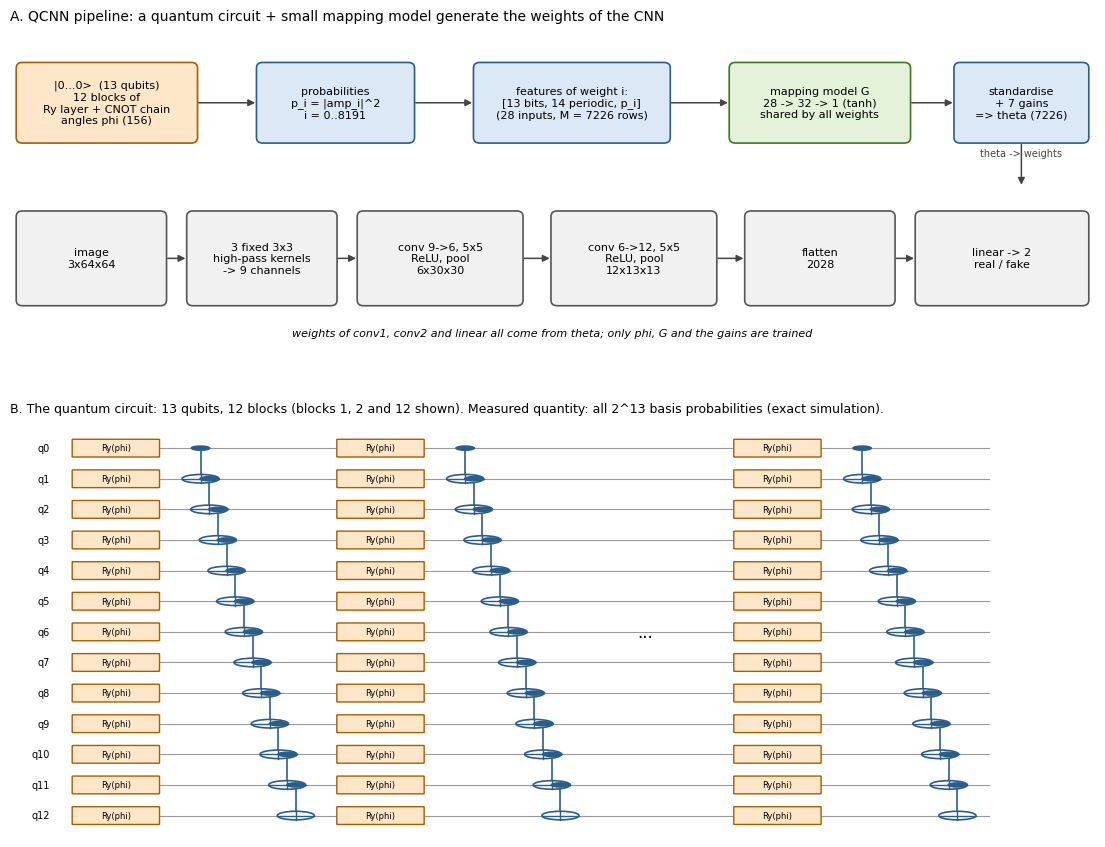

In [6]:
# ---- Architecture of the models (built from the live classes, so the numbers always match the code) ----
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch
_img = CFG['IMG']
_cnn = FuncCNN(_img); _qt = QCNN(_img, None, CFG['QT_BLOCKS'], CFG['MAP_HIDDEN'])

# 1) text summary
k = 5; s1 = (_img - k + 1) // 2; s2 = (s1 - k + 1) // 2
print('=== Target CNN (its weights are generated by the quantum circuit) ===')
print(f'input 3x{_img}x{_img}  -> {_cnn.K} fixed 3x3 high-pass kernel(s) per colour channel = {3*_cnn.K} channels (reflect pad), each divided by its calibration std')
print(f'conv1 {3*_cnn.K}->6, 5x5 + ReLU + maxpool2   -> 6x{s1}x{s1}')
print(f'conv2 6->12, 5x5 + ReLU + maxpool2  -> 12x{s2}x{s2}')
print(f'flatten {12*s2*s2} -> linear -> 2 logits')
for n_, sh in _cnn.shapes: print(f'   {n_:4s} {str(tuple(sh)):16s} {int(np.prod(sh)):6d} params')
print(f'   total M = {_cnn.M} weights\n')
print('=== QCNN: the CNN weights are NOT trained directly; they are generated ===')
print(f'QNN: {_qt.N} qubits (2^{_qt.N} = {2**_qt.N} amplitudes >= M), {_qt.nb} blocks of [Ry on every qubit -> CNOT chain] -> {_qt.nb*_qt.N} trainable angles phi')
print(f'for weight i: features = [{_qt.N} bits of i, {2*_qt.nf} periodic position features, rescaled probability p_i = |<i|psi(phi)>|^2]  ({_qt.G[0].in_features} numbers)')
print(f'mapping model G: Linear({_qt.G[0].in_features},{CFG["MAP_HIDDEN"]}) -> tanh -> Linear({CFG["MAP_HIDDEN"]},1)   (shared across all weights)')
print(f'per-tensor standardise (zero mean, unit std, He scale) x {len(_qt.f.shapes)} learnable gains + 1 channel-mean gain for the last layer')
print(f'trainable: phi {_qt.phi.numel()} + G {sum(p.numel() for p in _qt.G.parameters())} + gains {_qt.gain.numel()} = {_qt.n_trainable()}  ({_qt.n_trainable()/_qt.M:.1%} of M = {_qt.M})\n')

# 2) drawing helpers
def box(ax, x, y, w, h, text, fc='#dbe9f6', ec='#2b5d8a', fs=8):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs)
def arrow(ax, x0, y0, x1, y1, text=None):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>', mutation_scale=10, lw=1.1, color='#444'))
    if text: ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, text, ha='center', fontsize=7, color='#444')

def draw_circuit(ax, n, cols, ylabels=None, title=''):
    """cols: list of ('ry', label) | ('cnot', [(c,t),...]) | ('dots', '') | ('meas', '')."""
    ax.set_xlim(-0.8, len(cols) + 0.4); ax.set_ylim(-n + 0.3, 0.9); ax.axis('off'); ax.set_title(title, fontsize=9, loc='left')
    for q in range(n):
        ax.plot([-0.3, len(cols) - 0.4], [-q, -q], color='#999', lw=0.8, zorder=0)
        ax.text(-0.5, -q, ylabels[q] if ylabels else f'q{q}', ha='right', va='center', fontsize=7)
    for j, (kind, arg) in enumerate(cols):
        if kind == 'ry':
            for q in range(n):
                ax.add_patch(FancyBboxPatch((j - 0.32, -q - 0.28), 0.64, 0.56, boxstyle='round,pad=0.01', fc='#fde7c8', ec='#a85d00', lw=1)); ax.text(j, -q, arg, ha='center', va='center', fontsize=6)
        elif kind == 'cnot':
            chain = len(arg) > 1 and arg[0][1] == arg[1][0]          # sequential CNOT chain: spread the gates sideways so they do not overlap
            for i_, (c, t) in enumerate(arg):
                jx = j - 0.36 + 0.72 * i_ / (len(arg) - 1) if chain else j
                ax.plot([jx, jx], [-c, -t], color='#2b5d8a', lw=1.2); ax.add_patch(Circle((jx, -c), 0.07, color='#2b5d8a', zorder=3))
                ax.add_patch(Circle((jx, -t), 0.14, fc='white', ec='#2b5d8a', lw=1.2, zorder=3)); ax.plot([jx - 0.14, jx + 0.14], [-t, -t], color='#2b5d8a', lw=1, zorder=4); ax.plot([jx, jx], [-t - 0.14, -t + 0.14], color='#2b5d8a', lw=1, zorder=4)
        elif kind == 'meas':
            for q in range(n): ax.add_patch(FancyBboxPatch((j - 0.32, -q - 0.28), 0.64, 0.56, boxstyle='round,pad=0.01', fc='#e3f2d9', ec='#3b7a1f', lw=1)); ax.text(j, -q, '<Z>', ha='center', va='center', fontsize=6)
        elif kind == 'dots': ax.text(j, -(n - 1) / 2, arg, ha='center', va='center', fontsize=12)

fig = plt.figure(figsize=(14, 10.5)); gs = fig.add_gridspec(2, 1, height_ratios=[1.25, 1.6], hspace=0.18)

# A) QT-CNN pipeline
ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 14); ax.set_ylim(0, 4.6); ax.axis('off'); ax.set_title('A. QCNN pipeline: a quantum circuit + small mapping model generate the weights of the CNN', fontsize=10, loc='left')
box(ax, 0.1, 3.0, 2.3, 1.1, f'|0...0>  ({_qt.N} qubits)\n{_qt.nb} blocks of\nRy layer + CNOT chain\nangles phi ({_qt.phi.numel()})', fc='#fde7c8', ec='#a85d00')
box(ax, 3.2, 3.0, 2.0, 1.1, f'probabilities\np_i = |amp_i|^2\ni = 0..{2**_qt.N-1}')
box(ax, 6.0, 3.0, 2.5, 1.1, f'features of weight i:\n[{_qt.N} bits, {2*_qt.nf} periodic, p_i]\n({_qt.G[0].in_features} inputs, M = {_qt.M} rows)')
box(ax, 9.3, 3.0, 2.3, 1.1, f'mapping model G\n{_qt.G[0].in_features} -> {CFG["MAP_HIDDEN"]} -> 1 (tanh)\nshared by all weights', fc='#e3f2d9', ec='#3b7a1f')
box(ax, 12.2, 3.0, 1.7, 1.1, f'standardise\n+ {_qt.gain.numel()} gains\n=> theta ({_qt.M})')
for x0, x1 in [(2.4, 3.2), (5.2, 6.0), (8.5, 9.3), (11.6, 12.2)]: arrow(ax, x0, 3.55, x1, 3.55)
arrow(ax, 13.05, 3.0, 13.05, 2.35, 'theta -> weights')
y0 = 0.7; h = 1.3
stages = [(0.1, 1.9, f'image\n3x{_img}x{_img}'), (2.3, 1.9, f'{_cnn.K} fixed 3x3\nhigh-pass kernels\n-> {3*_cnn.K} channels'), (4.5, 2.1, f'conv {3*_cnn.K}->6, 5x5\nReLU, pool\n6x{s1}x{s1}'), (7.0, 2.1, f'conv 6->12, 5x5\nReLU, pool\n12x{s2}x{s2}'), (9.5, 1.9, f'flatten\n{12*s2*s2}'), (11.7, 2.2, 'linear -> 2\nreal / fake')]
for x, w, t in stages: box(ax, x, y0, w, h, t, fc='#f1f1f1', ec='#555')
for (x, w, _), (x2, _, _) in zip(stages[:-1], stages[1:]): arrow(ax, x + w, y0 + h / 2, x2, y0 + h / 2)
ax.text(7.0, 0.25, 'weights of conv1, conv2 and linear all come from theta; only phi, G and the gains are trained', ha='center', fontsize=8, style='italic')

# B) QNN circuit (first 2 blocks, last block)
ax = fig.add_subplot(gs[1]); N = _qt.N
cols = [('ry', 'Ry(phi)'), ('cnot', [(i, i + 1) for i in range(N - 1)]), ('ry', 'Ry(phi)'), ('cnot', [(i, i + 1) for i in range(N - 1)]), ('dots', '...'), ('ry', 'Ry(phi)'), ('cnot', [(i, i + 1) for i in range(N - 1)])]
draw_circuit(ax, N, cols, title=f'B. The quantum circuit: {N} qubits, {_qt.nb} blocks (blocks 1, 2 and {_qt.nb} shown). Measured quantity: all 2^{N} basis probabilities (exact simulation).')

for ext in ('png', 'pdf', 'svg'): plt.savefig(f'architecture_{DS_NAME}.{ext}', dpi=300 if ext == 'png' else None, bbox_inches='tight')   # png for slides, pdf/svg for the paper\nplt.show()


## Training and evaluation helpers

In [7]:
def metrics(y, p, thr=0.5):
    fpr, tpr, _ = roc_curve(y, p); fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr))); eer = float((fpr[i] + fnr[i]) / 2)
    return dict(acc=float(((p > thr) == y).mean()), auc=float(roc_auc_score(y, p)), eer=eer, tpr_at_1pct_fpr=float(np.interp(0.01, fpr, tpr)))

def best_threshold(y, p):
    """Decision threshold maximising TPR - FPR (Youden's J) on a labelled set; use the validation set, never the test set."""
    fpr, tpr, th = roc_curve(y, p); ok = np.isfinite(th)
    return float(np.clip(th[ok][np.argmax((tpr - fpr)[ok])], 0.05, 0.95))

def auc_ci(y, p, n=1000, seed=0):
    """Bootstrap 95% confidence interval of the AUC."""
    rng = np.random.default_rng(seed); a = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max(): a.append(roc_auc_score(y[i], p[i]))
    return tuple(float(v) for v in np.percentile(a, [2.5, 97.5]))

@torch.no_grad()
def predict(model, X, bs=512, tta=True):
    """P(fake) for every image in X (average over the image and its mirror when tta). The CNN weights are generated once, then reused for all batches."""
    model.eval(); th = model.gen_theta(); ps = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]; p = F.softmax(model(xb, th), 1)[:, 1]
        if tta: p = (p + F.softmax(model(xb.flip(3), th), 1)[:, 1]) / 2
        ps.append(p)
    return torch.cat(ps).cpu().numpy()

def fit(model, tr, va, aug=None, verbose=True):
    """AdamW (weight decay on the mapping network only) + linear warm-up and cosine decay per step; the epoch with the best validation AUC is kept.
    aug: larger training tensor -> random crop + flip each batch."""
    model.to(dev)
    decay = [p for n, p in model.named_parameters() if n.startswith('G.') and p.ndim > 1]
    rest = [p for n, p in model.named_parameters() if not (n.startswith('G.') and p.ndim > 1)]
    opt = torch.optim.AdamW([dict(params=rest, weight_decay=0.), dict(params=decay, weight_decay=CFG['WD'])], lr=CFG['LR'])
    src = aug if aug is not None else tr
    spe = math.ceil(len(src[0]) / CFG['BS']); total = CFG['EPOCHS'] * spe; warm = max(int(CFG['WARMUP'] * spe), 1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    yv = va[1].cpu().numpy(); best, best_state, best_ep, hist, t0 = -1, None, 0, [], time.time()
    for ep in range(CFG['EPOCHS']):
        model.train(); tot = 0.
        for x, y in batches(src[0], src[1], CFG['BS'], True):
            if aug is not None: x = augment(x, CFG['IMG'])
            loss = F.cross_entropy(model(x), y); opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG['CLIP']); opt.step(); sched.step(); tot += loss.detach() * len(x)
        v = metrics(yv, predict(model, va[0])); hist.append(dict(epoch=ep + 1, loss=float(tot) / len(src[0]), val_auc=v['auc'], val_acc=v['acc'], t_cum=time.time() - t0))
        if v['auc'] > best: best, best_ep, best_state = v['auc'], ep + 1, {k: t.clone() for k, t in model.state_dict().items()}
        if verbose: print(f"ep{ep + 1:02d}  loss {hist[-1]['loss']:.4f}  val acc {v['acc']:.3f}  val auc {v['auc']:.3f}")
    model.load_state_dict(best_state)
    return hist, best_ep, time.time() - t0


## Self-test (simulator, QCNN, augmentation)

In [8]:
def selftest():
    # simulator vs dense matrices, norm preservation, gradient flow into the circuit angles
    n = 4; g = torch.Generator().manual_seed(0)
    st = torch.randn(2 ** n, generator=g); st /= st.norm(); a = torch.rand(n, generator=g) * 3
    def dense_ry(k, t):
        c, s = math.cos(t / 2), math.sin(t / 2); R = torch.tensor([[c, -s], [s, c]]); m = torch.eye(1)
        for j in range(n): m = torch.kron(m, R if j == k else torch.eye(2))
        return m
    d, v = st.clone(), st.clone()
    for k in range(n): d = dense_ry(k, float(a[k])) @ d; v = ry(v, k, n, a[k])
    assert torch.allclose(d, v, atol=1e-6), 'Ry does not match the dense matrix'
    pr = [(i, (i + 1) % n) for i in range(n)]
    for c, t in pr:
        M = torch.zeros(2 ** n, 2 ** n)
        for i in range(2 ** n): M[i ^ (((i >> (n - 1 - c)) & 1) << (n - 1 - t)), i] = 1
        d = M @ d
    assert torch.allclose(d, v[cnot_perm(n, pr)], atol=1e-6), 'CNOT permutation does not match the dense matrix'
    img = CFG['IMG']; q = QCNN(img, torch.rand(8, 3, img, img), CFG['QT_BLOCKS'], CFG['MAP_HIDDEN'])
    assert abs(float(q.qnn_state().detach().norm()) - 1) < 1e-5, 'QNN state not normalised'
    out = q(torch.rand(2, 3, img, img)); assert out.shape == (2, 2)
    assert q.f._residual(torch.rand(2, 3, img, img)).shape[1] == 3 * q.f.K, 'wrong number of residual channels'
    assert q.G[0].in_features == q.N + 2 * q.nf + 1 and q.pos.shape == (q.M, 2 * q.nf), 'feature size mismatch'
    o64 = q(torch.rand(64, 3, img, img)); assert float((o64[:, 1] - o64[:, 0]).mean().abs()) < 2.0 and float(o64.std()) < 1.5, 'initial logits too large or class offset too big'
    p0 = predict(q, torch.rand(6, 3, img, img), tta=False); p1 = predict(q, torch.rand(6, 3, img, img).flip(3), tta=False); assert p0.shape == (6,)
    out.sum().backward(); assert q.phi.grad is not None and float(q.phi.grad.abs().sum()) > 0, 'no gradient into QNN angles'
    print(f'self-test OK | target CNN M = {q.M} weights, {q.N} qubits, trainable = {q.n_trainable()} ({q.n_trainable() / q.M:.1%} of M)')
selftest()

def selftest_aug():
    x = torch.rand(5, 3, 80, 80); a = augment(x, 64); assert a.shape == (5, 3, 64, 64)
    assert centre(x, 64).shape == (5, 3, 64, 64) and torch.equal(centre(x, 64), x[..., 8:72, 8:72])
    y = torch.arange(64.).view(1, 1, 8, 8).repeat(1, 3, 1, 1)            # size == H: output must be the image or its mirror
    for _ in range(20):
        w = augment(y, 8)[0, 0]; assert torch.equal(w, y[0, 0]) or torch.equal(w, y[0, 0].flip(1)), 'augment must give identity or flip'
    print('augment self-test OK')
selftest_aug()


/tmp/ipykernel_578/1145345007.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  o64 = q(torch.rand(64, 3, img, img)); assert float((o64[:, 1] - o64[:, 0]).mean().abs()) < 2.0 and float(o64.std()) < 1.5, 'initial logits too large or class offset too big'


self-test OK | target CNN M = 7226 weights, 13 qubits, trainable = 1124 (15.6% of M)
augment self-test OK


## Train the QCNN

In [9]:
data = load_data()
img = CFG['IMG']; tr, va, te = data['train'], data['valid'], data['test']
aug = data['train_aug'] if CFG['AUGMENT'] else None

seed_all(CFG['SEED'])
model = QCNN(img, tr[0], CFG['QT_BLOCKS'], CFG['MAP_HIDDEN'])      # tr[0]: calibrates the input scale of the high-pass residual
print(f'target CNN: {model.M} weights | QNN: {model.N} qubits x {model.nb} blocks | trainable parameters: {model.n_trainable()} ({model.n_trainable() / model.M:.1%} of the CNN weights)')
hist, best_ep, train_s = fit(model, tr, va, aug=aug)
model.thr = best_threshold(va[1].cpu().numpy(), predict(model, va[0]))        # decision threshold from the validation set (the test set is not touched)
print(f'best epoch {best_ep}, training time {train_s:.0f} s, decision threshold (validation) {model.thr:.3f}')
save_qcnn(model, CFG['CKPT'], extra=dict(best_ep=best_ep, thr=model.thr)); print('saved ->', CFG['CKPT'])


faces140k root: /content/real_vs_fake/real_vs_fake/real-vs-fake
train (20000, 3, 64, 64) fake 0.50 | valid (4000, 3, 64, 64) fake 0.50 | test (10000, 3, 64, 64) fake 0.50
target CNN: 7226 weights | QNN: 13 qubits x 12 blocks | trainable parameters: 1124 (15.6% of the CNN weights)
ep01  loss 0.7486  val acc 0.590  val auc 0.633
ep02  loss 0.6877  val acc 0.595  val auc 0.648
ep03  loss 0.6821  val acc 0.673  val auc 0.747
ep04  loss 0.6615  val acc 0.592  val auc 0.738
ep05  loss 0.6236  val acc 0.682  val auc 0.798
ep06  loss 0.6071  val acc 0.679  val auc 0.806
ep07  loss 0.5903  val acc 0.634  val auc 0.811
ep08  loss 0.5740  val acc 0.710  val auc 0.820
ep09  loss 0.5589  val acc 0.653  val auc 0.812
ep10  loss 0.5616  val acc 0.754  val auc 0.830
ep11  loss 0.5510  val acc 0.747  val auc 0.832
ep12  loss 0.5497  val acc 0.740  val auc 0.832
ep13  loss 0.5453  val acc 0.736  val auc 0.842
ep14  loss 0.5299  val acc 0.762  val auc 0.844
ep15  loss 0.5349  val acc 0.768  val auc 0.844

## Test-set results

test set (10000 images): AUC 0.8585 (95% CI 0.852-0.866) | EER 0.2243 | TPR at 1% FPR 0.3462 | accuracy 0.7787 at 0.5, 0.7772 at the validation threshold 0.530
confusion matrix at the validation threshold (rows = truth, columns = prediction):  real: 4253 correct, 747 called fake  |  fake: 1481 called real, 3519 correct
half-cut entanglement entropy of the trained circuit state: 5.48 bits


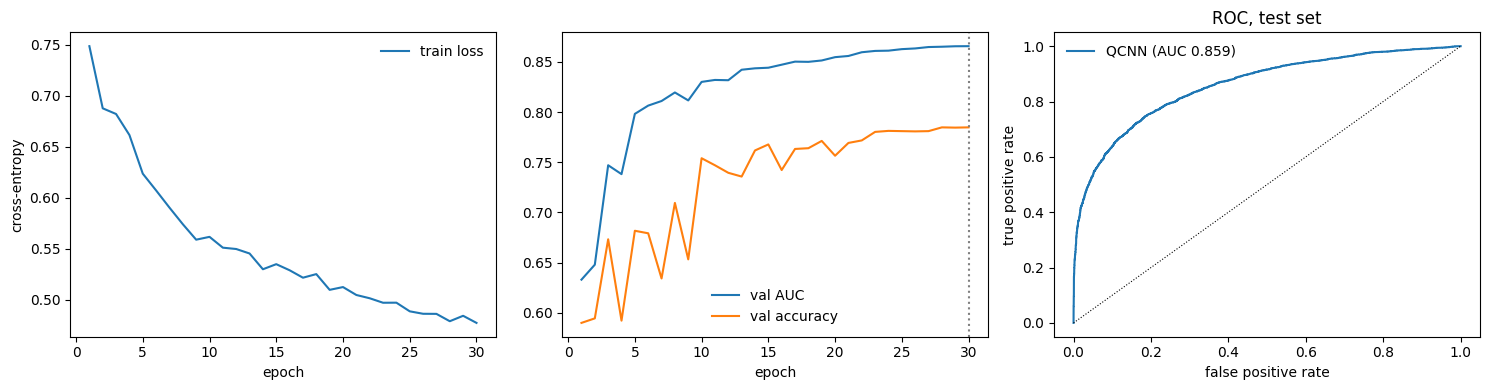

In [10]:
if data['synthetic']: print('DATA: SYNTHETIC   <-- smoke test, not real-vs-fake results')
yt = te[1].cpu().numpy(); pt = predict(model, te[0]); R = metrics(yt, pt); thr = getattr(model, 'thr', 0.5); Rt = metrics(yt, pt, thr); lo, hi = auc_ci(yt, pt)
pred = (pt > thr).astype(int); TN = int(((pred == 0) & (yt == 0)).sum()); FP = int(((pred == 1) & (yt == 0)).sum()); FN = int(((pred == 0) & (yt == 1)).sum()); TP = int(((pred == 1) & (yt == 1)).sum())
print(f"test set ({len(yt)} images): AUC {R['auc']:.4f} (95% CI {lo:.3f}-{hi:.3f}) | EER {R['eer']:.4f} | TPR at 1% FPR {R['tpr_at_1pct_fpr']:.4f} | accuracy {R['acc']:.4f} at 0.5, {Rt['acc']:.4f} at the validation threshold {thr:.3f}")
print(f'confusion matrix at the validation threshold (rows = truth, columns = prediction):  real: {TN} correct, {FP} called fake  |  fake: {FN} called real, {TP} correct')
print(f'half-cut entanglement entropy of the trained circuit state: {half_cut_entropy(model.qnn_state(), model.N):.2f} bits')
json.dump(dict(cfg=CFG, test=R, test_at_val_threshold=Rt, threshold=thr, auc_ci95=[lo, hi], confusion=dict(TN=TN, FP=FP, FN=FN, TP=TP), best_epoch=best_ep, history=hist, train_seconds=train_s, torch=torch.__version__,
               synthetic_data=bool(data['synthetic'])), open(f'results_{DS_NAME}.json', 'w'), indent=1, default=str)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ep = [h['epoch'] for h in hist]
ax[0].plot(ep, [h['loss'] for h in hist], label='train loss'); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('cross-entropy'); ax[0].legend(frameon=False)
ax[1].plot(ep, [h['val_auc'] for h in hist], label='val AUC'); ax[1].plot(ep, [h['val_acc'] for h in hist], label='val accuracy'); ax[1].axvline(best_ep, color='gray', ls=':'); ax[1].set_xlabel('epoch'); ax[1].legend(frameon=False)
fpr, tpr, _ = roc_curve(yt, pt); ax[2].plot(fpr, tpr, label=f"QCNN (AUC {R['auc']:.3f})"); ax[2].plot([0, 1], [0, 1], 'k:', lw=0.8)
ax[2].set_xlabel('false positive rate'); ax[2].set_ylabel('true positive rate'); ax[2].set_title('ROC, test set'); ax[2].legend(frameon=False)
plt.tight_layout(); plt.savefig(f'fig_{DS_NAME}.png', dpi=200); plt.show()


## Computation time and cost
Measured on the current device (`dev`): cost of the quantum-circuit simulation, one-off weight generation, inference latency / throughput, training-step time against the same CNN trained directly, and the multiply-accumulate count of the target CNN. Saved as `time_faces140k.png` / `.pdf` and `timing_faces140k.json`. Run it after training, on the GPU you used for training, and note the GPU model when you quote the numbers.


device: Tesla T4
target CNN: 7226 weights, 6.41 M multiply-accumulates per image  high_pass 0.33M | conv1 4.86M | conv2 1.22M | linear 0.00M
quantum circuit: 13 qubits, 156 Ry gates + 144 CNOTs on a 8192-amplitude statevector: 30.97 ms
generate all 7226 weights (circuit + mapping net): 26.18 ms, done ONCE; afterwards inference is an ordinary CNN
inference, batch     1:     0.55 ms per batch |   0.554 ms per image |      1805 images/s
inference, batch    16:     1.14 ms per batch |   0.071 ms per image |     14063 images/s
inference, batch    64:     2.30 ms per batch |   0.036 ms per image |     27836 images/s
inference, batch   256:     8.29 ms per batch |   0.032 ms per image |     30862 images/s
inference, batch  1024:    26.50 ms per batch |   0.026 ms per image |     38648 images/s
training step (batch 128): QCNN 120.2 ms vs direct CNN 11.0 ms  (10.9x)   peak GPU memory 2843 vs 2836 MB
trainable parameters: QCNN 1124 vs direct CNN 7226 (15.6%)
training run: 614 s for 30 epochs, me

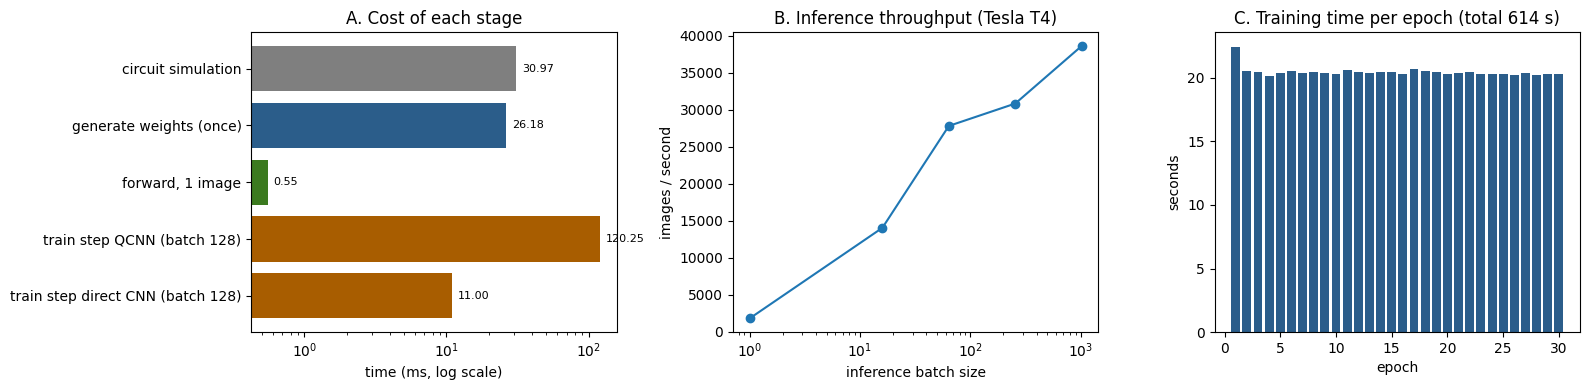

In [11]:
import copy
def sync():
    if dev == 'cuda': torch.cuda.synchronize()
def timeit(fn, n=10, warm=2):
    for _ in range(warm): fn()
    sync(); t0 = time.perf_counter()
    for _ in range(n): fn()
    sync(); return (time.perf_counter() - t0) / n

f = model.f; img = CFG['IMG']; bs = CFG['BS']; dev_name = torch.cuda.get_device_name(0) if dev == 'cuda' else 'CPU'

# ---- analytic cost of the target CNN (multiply-accumulates for one image)
k = 5; H1 = img - k + 1; H2 = H1 // 2 - k + 1
macs = dict(high_pass=(3 * f.K * 9 * img * img if CFG['HIGHPASS'] else 0), conv1=int(np.prod(f.shapes[0][1])) * H1 * H1,
            conv2=int(np.prod(f.shapes[2][1])) * H2 * H2, linear=int(np.prod(f.shapes[4][1])))
macs_total = sum(macs.values())

# ---- inference: weight generation (once) and forward passes
model.eval()
with torch.no_grad():
    t_sim = timeit(model.qnn_state); t_gen = timeit(model.gen_theta); th = model.gen_theta()
    sweep = {}
    for b in [1, 16, 64, 256, 1024]:
        if b <= len(te[0]): xb_ = te[0][:b]; sweep[b] = timeit(lambda: model(xb_, th), n=10 if b < 256 else 5)

# ---- training step (forward + backward + Adam) on a batch of BS: QCNN vs the same CNN with directly trained weights
def step_time(m, x, y):
    m = m.to(dev).train(); opt = torch.optim.Adam(m.parameters(), lr=1e-4)
    def step():
        loss = F.cross_entropy(m(x), y); opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    if dev == 'cuda': torch.cuda.reset_peak_memory_stats()
    t = timeit(step, n=5, warm=1)
    return t, (torch.cuda.max_memory_allocated() / 2 ** 20 if dev == 'cuda' else float('nan'))
class DirectCNN(nn.Module):
    def __init__(s, f): super().__init__(); s.f = f; s.theta = nn.Parameter(f.init_theta())
    def forward(s, x): return s.f.forward(x, s.theta)
xb, yb = tr[0][:bs], tr[1][:bs]
t_qt, mem_qt = step_time(copy.deepcopy(model), xb, yb)           # copy: the trained model is not modified
direct = DirectCNN(f); t_dir, mem_dir = step_time(direct, xb, yb)
ep_s = np.diff([0.] + [h['t_cum'] for h in hist])                # seconds per epoch of the training run above (includes validation)

print(f'device: {dev_name}')
print(f'target CNN: {f.M} weights, {macs_total / 1e6:.2f} M multiply-accumulates per image  ' + ' | '.join(f'{k_} {v / 1e6:.2f}M' for k_, v in macs.items()))
print(f'quantum circuit: {model.N} qubits, {model.nb * model.N} Ry gates + {model.nb * (model.N - 1)} CNOTs on a {2 ** model.N}-amplitude statevector: {t_sim * 1e3:.2f} ms')
print(f'generate all {f.M} weights (circuit + mapping net): {t_gen * 1e3:.2f} ms, done ONCE; afterwards inference is an ordinary CNN')
for b, t in sweep.items(): print(f'inference, batch {b:5d}: {t * 1e3:8.2f} ms per batch | {t / b * 1e3:7.3f} ms per image | {b / t:9.0f} images/s')
print(f'training step (batch {bs}): QCNN {t_qt * 1e3:.1f} ms vs direct CNN {t_dir * 1e3:.1f} ms  ({t_qt / t_dir:.1f}x)   peak GPU memory {mem_qt:.0f} vs {mem_dir:.0f} MB')
print(f'trainable parameters: QCNN {model.n_trainable()} vs direct CNN {f.M} ({model.n_trainable() / f.M:.1%})')
print(f'training run: {ep_s.sum():.0f} s for {len(ep_s)} epochs, mean {ep_s.mean():.1f} s per epoch')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
lab = ['circuit simulation', 'generate weights (once)', 'forward, 1 image', f'train step QCNN (batch {bs})', f'train step direct CNN (batch {bs})']
val = [t_sim, t_gen, sweep.get(1, np.nan), t_qt, t_dir]
ax[0].barh(lab[::-1], np.array(val[::-1]) * 1e3, color=['#7f7f7f', '#2b5d8a', '#3b7a1f', '#a85d00', '#a85d00'][::-1]); ax[0].set_xscale('log'); ax[0].set_xlabel('time (ms, log scale)'); ax[0].set_title('A. Cost of each stage')
for y_, v_ in enumerate(np.array(val[::-1]) * 1e3): ax[0].text(v_ * 1.1, y_, f'{v_:.2f}', va='center', fontsize=8)
bb = list(sweep); ax[1].plot(bb, [b / sweep[b] for b in bb], 'o-'); ax[1].set_xscale('log'); ax[1].set_xlabel('inference batch size'); ax[1].set_ylabel('images / second'); ax[1].set_title(f'B. Inference throughput ({dev_name})')
ax[2].bar(np.arange(1, len(ep_s) + 1), ep_s, color='#2b5d8a'); ax[2].set_xlabel('epoch'); ax[2].set_ylabel('seconds'); ax[2].set_title(f'C. Training time per epoch (total {ep_s.sum():.0f} s)')
plt.tight_layout()
for ext in ('png', 'pdf'): plt.savefig(f'time_{DS_NAME}.{ext}', dpi=300 if ext == 'png' else None, bbox_inches='tight')
plt.show()
json.dump(dict(device=dev_name, torch=torch.__version__, weights=f.M, macs=macs, macs_total=macs_total, sim_s=t_sim, gen_weights_s=t_gen,
               inference_s_per_batch={str(b): t for b, t in sweep.items()}, train_step_s=dict(qcnn=t_qt, direct=t_dir), peak_mem_mb=dict(qcnn=mem_qt, direct=mem_dir),
               trainable=dict(qcnn=model.n_trainable(), direct=f.M), epoch_s=[float(v) for v in ep_s], train_total_s=float(ep_s.sum())), open(f'timing_{DS_NAME}.json', 'w'), indent=1)


## Use the trained QCNN on an image
`detect(path)` returns P(fake). The image is preprocessed exactly as in training (centre 64 x 64 native-pixel patch, or the whole face resized, depending on `CFG['MODE']`) and the average over the image and its mirror is used. The REAL/FAKE call uses the decision threshold picked on the validation set (`model.thr`).
The model was trained on 256 x 256 face images; for photos with a very different resolution or heavy compression the output is not reliable.

In [12]:
@torch.no_grad()
def detect(path, model=None, tta=True):
    """Probability that the image is fake (generated). Label 1 = fake, 0 = real."""
    model = model if model is not None else globals()['model']
    model.eval(); th = model.gen_theta(); x = preprocess_image(path)
    xs = [x, x.flip(3)] if tta else [x]
    p = float(torch.stack([F.softmax(model(v, th), 1)[0, 1] for v in xs]).mean()); thr = getattr(model, 'thr', 0.5)
    print(f"{os.path.basename(path)}: P(fake) = {p:.3f} -> {'FAKE (generated)' if p > thr else 'REAL'}  (threshold {thr:.2f})")
    return p

# demo on three test-set images of each class (uses the dataset folder; skipped for synthetic data)
if not data['synthetic']:
    root = find_data_root(CFG['DATA_DIR']); tdir = next(os.path.join(root, s) for s in ('test',) if os.path.isdir(os.path.join(root, s)))
    for cls in ('real', 'fake'):
        for f in sorted(glob.glob(os.path.join(tdir, cls, '*')))[:3]: print(f'[true: {cls}]', end=' '); detect(f)


[true: real] 00001.jpg: P(fake) = 0.146 -> REAL  (threshold 0.53)
[true: real] 00004.jpg: P(fake) = 0.644 -> FAKE (generated)  (threshold 0.53)
[true: real] 00007.jpg: P(fake) = 0.381 -> REAL  (threshold 0.53)
[true: fake] 00276TOPP4.jpg: P(fake) = 0.482 -> REAL  (threshold 0.53)
[true: fake] 008BYSE725.jpg: P(fake) = 0.966 -> FAKE (generated)  (threshold 0.53)
[true: fake] 009ZTJ3621.jpg: P(fake) = 0.662 -> FAKE (generated)  (threshold 0.53)


In [ ]:
# Upload your own images (Colab). To use a saved model in a fresh session: model = load_qcnn(CFG['CKPT']) after running the cells that define the classes.
try:
    from google.colab import files
    up = files.upload()
    for fn in up: detect(fn)
except ImportError:
    print('not running in Colab: call detect("path/to/image.jpg") directly')


## Optional: which change helps? (ablation)
Set `RUN_ABLATION = True` to train four variants on the data above (same splits, 2 seeds each) and print mean test AUC. Each run takes a few minutes on a T4, so the whole cell takes roughly 30-40 minutes with the default settings; lower `EPOCHS` in the cell for a quicker look. Your trained `model` above is not touched. All four variants include the optimiser changes and the final-layer offset fix; the ablation only switches the front end (1 vs 3 kernels), the position features and the mapping-network width. To compare against the exact old behaviour, rerun the original notebook.


In [ ]:
RUN_ABLATION = False
if RUN_ABLATION:
    variants = {
        'old front end + G (1 kernel, no pos, hidden 20)': dict(HP_MODE='single', POS_FEATS=False, MAP_HIDDEN=20),
        '+ multi high-pass only':                       dict(HP_MODE='multi',  POS_FEATS=False, MAP_HIDDEN=20),
        '+ position feats + hidden 32 only':            dict(HP_MODE='single', POS_FEATS=True,  MAP_HIDDEN=32),
        'new (all changes, default)':                   dict(),
    }
    base = dict(CFG); yt = te[1].cpu().numpy(); rows = []
    for name, ov in variants.items():
        aucs = []
        for s in (0, 1):
            CFG.update(base); CFG.update(ov); seed_all(s)
            m = QCNN(img, tr[0], CFG['QT_BLOCKS'], CFG['MAP_HIDDEN']); fit(m, tr, va, aug=aug, verbose=False)
            aucs.append(metrics(yt, predict(m, te[0]))['auc'])
        rows.append((name, float(np.mean(aucs)), aucs, m.n_trainable())); print(f'{name:48s} mean test AUC {np.mean(aucs):.4f}  runs {[round(a, 4) for a in aucs]}  trainable {m.n_trainable()}')
    CFG.update(base)
    print('with only 2 seeds, differences below about 0.01 AUC are within run-to-run noise')


## Benchmark: QCNN vs standard CNNs (accuracy and computation time)
A fair comparison under three conditions, same data, same front end, same optimiser, several seeds, and several training-set sizes:
1. **QCNN** (this notebook): about 1,100 trainable parameters generate the weights of the 7,226-weight CNN.
2. **CNN with the same trainable budget:** a small classical CNN (same fixed high-pass front end) sized to about the QCNN's trainable-parameter count. This is the fair test of the parameter-efficiency claim.
3. **CNN, same architecture, weights trained directly:** an upper-reference, 7,226 trainable parameters.

What can and cannot be claimed: after training, QCNN inference is an ordinary CNN forward pass, so inference time equals that of condition 3 by construction. On classical hardware the circuit has to be simulated (cost grows as 2^qubits), so training is not faster than condition 3. The expected benefit is fewer trainable and stored parameters, and possibly better accuracy than a classical CNN of the same trainable size, especially with little data. The cell reports what it measures; use the printed numbers, not the expectation, in the paper.

`RUN_BENCH = True` trains 3 models x seeds x data fractions (about 6 min per run on a T4 at the default 20k images and 30 epochs; lower `EPOCHS` or `BENCH_SEEDS` for a first look).


In [ ]:
RUN_BENCH = False
BENCH_SEEDS = (0, 1, 2)
BENCH_FRACS = (0.1, 0.3, 1.0)          # fraction of the training set used (low-data regime first)

class SmallCNN(nn.Module):
    """Classical CNN with about `budget` trainable parameters (same fixed high-pass front end, 2 conv layers, 2x2 average pooling, linear)."""
    def __init__(s, img, budget, calib):
        super().__init__(); s.front = FuncCNN(img, calib=calib); cin = 3 * s.front.K; best = None
        for c1 in range(1, 17):
            for c2 in range(1, 17):
                n = c1 * cin * 25 + c1 + c2 * c1 * 25 + c2 + 2 * c2 * 4 + 2
                if n <= budget and (best is None or n > best[0]): best = (n, c1, c2)
        _, c1, c2 = best; s.widths = (c1, c2)
        s.conv1 = nn.Conv2d(cin, c1, 5); s.conv2 = nn.Conv2d(c1, c2, 5); s.fc = nn.Linear(c2 * 4, 2)
    def gen_theta(s): return None
    def forward(s, x, theta=None):
        x = s.front._residual(x) / s.front.scale if CFG['HIGHPASS'] else (x - 0.5) / 0.5
        x = F.max_pool2d(F.relu(s.conv1(x)), 2); x = F.max_pool2d(F.relu(s.conv2(x)), 2)
        return s.fc(F.adaptive_avg_pool2d(x, 2).flatten(1))
    def n_trainable(s): return sum(p.numel() for p in s.parameters())

class DirectCNN2(nn.Module):
    """The same CNN as the QCNN's target, with its weights trained directly."""
    def __init__(s, img, calib): super().__init__(); s.f = FuncCNN(img, calib=calib); s.theta = nn.Parameter(s.f.init_theta())
    def gen_theta(s): return s.theta
    def forward(s, x, theta=None): return s.f.forward(x, s.theta if theta is None else theta)
    def n_trainable(s): return s.theta.numel()

def _sync():
    if dev == 'cuda': torch.cuda.synchronize()

def bench_one(kind, seed, frac):
    seed_all(seed); g = torch.Generator().manual_seed(100 + seed)
    idx = torch.randperm(len(tr[0]), generator=g)[:max(int(len(tr[0]) * frac), CFG['BS'])].to(dev)
    sub = (tr[0][idx], tr[1][idx]); subaug = (aug[0][idx], aug[1][idx]) if aug is not None else None
    budget = QCNN(img, tr[0][:64], CFG['QT_BLOCKS'], CFG['MAP_HIDDEN']).n_trainable()
    m = {'QCNN': lambda: QCNN(img, tr[0], CFG['QT_BLOCKS'], CFG['MAP_HIDDEN']),
         'CNN, same trainable budget': lambda: SmallCNN(img, budget, tr[0]),
         'CNN, direct (same architecture)': lambda: DirectCNN2(img, tr[0])}[kind]()
    hist_, best_ep_, train_s_ = fit(m, sub, va, aug=subaug, verbose=False)
    thr_ = best_threshold(va[1].cpu().numpy(), predict(m, va[0])); yt_ = te[1].cpu().numpy(); pt_ = predict(m, te[0]); R_ = metrics(yt_, pt_, thr_)
    m.eval(); xb_ = te[0][:256]
    with torch.no_grad():
        th_ = m.gen_theta(); fwd = lambda: m(xb_, th_)
        for _ in range(2): fwd()
        _sync(); t0 = time.perf_counter()
        for _ in range(5): fwd()
        _sync(); inf_ms = (time.perf_counter() - t0) / 5 / len(xb_) * 1e3
    return dict(kind=kind, seed=seed, frac=frac, n_train=int(len(idx)), auc=R_['auc'], acc=R_['acc'], eer=R_['eer'], trainable=int(m.n_trainable()),
                train_s=train_s_, train_s_per_epoch=train_s_ / CFG['EPOCHS'], infer_ms_per_img=inf_ms, best_ep=best_ep_)

if RUN_BENCH:
    kinds = ['QCNN', 'CNN, same trainable budget', 'CNN, direct (same architecture)']; rows = []
    for fr in BENCH_FRACS:
        for kd in kinds:
            for sd in BENCH_SEEDS:
                r_ = bench_one(kd, sd, fr); rows.append(r_)
                print(f"frac {fr:.1f} | {kd:34s} seed {sd} | AUC {r_['auc']:.4f} acc {r_['acc']:.4f} | trainable {r_['trainable']:5d} | train {r_['train_s']:.0f} s | infer {r_['infer_ms_per_img']:.3f} ms/img", flush=True)
    json.dump(rows, open(f'benchmark_{DS_NAME}.json', 'w'), indent=1)

    def agg(kd, fr, key):
        v = np.array([r_[key] for r_ in rows if r_['kind'] == kd and r_['frac'] == fr]); return v.mean(), v.std()
    print('\n| training images | model | trainable params | test AUC | test acc | train time (s) | inference (ms/img) |\n|---|---|---|---|---|---|---|')
    for fr in BENCH_FRACS:
        for kd in kinds:
            a, sa = agg(kd, fr, 'auc'); c, sc = agg(kd, fr, 'acc'); t, _ = agg(kd, fr, 'train_s'); i_, _ = agg(kd, fr, 'infer_ms_per_img'); p, _ = agg(kd, fr, 'trainable'); n_ = [r_['n_train'] for r_ in rows if r_['frac'] == fr][0]
            print(f'| {n_} | {kd} | {int(p)} | {a:.4f} +- {sa:.4f} | {c:.4f} +- {sc:.4f} | {t:.0f} | {i_:.3f} |')
    print(f'\nmean over {len(BENCH_SEEDS)} seeds; +- is the std over seeds. Differences smaller than the std are not evidence of a difference.')
    for fr in BENCH_FRACS:
        q, sq = agg(kinds[0], fr, 'auc'); b, sb = agg(kinds[1], fr, 'auc'); d, sd_ = agg(kinds[2], fr, 'auc')
        print(f'frac {fr:.1f}: QCNN AUC - same-budget CNN = {q - b:+.4f} (stds {sq:.4f}/{sb:.4f}) | QCNN - direct CNN = {q - d:+.4f} (stds {sq:.4f}/{sd_:.4f})')

    fig, ax = plt.subplots(1, 3, figsize=(16, 4)); col = ['#a85d00', '#7f7f7f', '#2b5d8a']; xs = [max(int(len(tr[0]) * f_), CFG['BS']) for f_ in BENCH_FRACS]
    for kd, c_ in zip(kinds, col):
        mu = [agg(kd, f_, 'auc')[0] for f_ in BENCH_FRACS]; sd_ = [agg(kd, f_, 'auc')[1] for f_ in BENCH_FRACS]
        ax[0].errorbar(xs, mu, yerr=sd_, marker='o', capsize=3, label=f"{kd} ({int(agg(kd, BENCH_FRACS[-1], 'trainable')[0])} params)", color=c_)
    ax[0].set_xscale('log'); ax[0].set_xlabel('training images'); ax[0].set_ylabel('test AUC'); ax[0].set_title('A. Accuracy vs training-set size'); ax[0].legend(frameon=False, fontsize=7)
    w = 0.25; fl = np.arange(len(BENCH_FRACS))
    for j, (kd, c_) in enumerate(zip(kinds, col)): ax[1].bar(fl + (j - 1) * w, [agg(kd, f_, 'train_s')[0] for f_ in BENCH_FRACS], w, color=c_, label=kd)
    ax[1].set_xticks(fl); ax[1].set_xticklabels([str(x_) for x_ in xs]); ax[1].set_xlabel('training images'); ax[1].set_ylabel('training time (s)'); ax[1].set_title('B. Training time')
    ax[2].bar(range(3), [agg(kd, BENCH_FRACS[-1], 'infer_ms_per_img')[0] for kd in kinds], color=col); ax[2].set_xticks(range(3)); ax[2].set_xticklabels(['QCNN', 'CNN same\nbudget', 'CNN direct'])
    ax[2].set_ylabel('ms per image (batch 256)'); ax[2].set_title(f'C. Inference time ({torch.cuda.get_device_name(0) if dev == "cuda" else "CPU"})')
    plt.tight_layout()
    for ext in ('png', 'pdf'): plt.savefig(f'benchmark_{DS_NAME}.{ext}', dpi=300 if ext == 'png' else None, bbox_inches='tight')
    plt.show()


## Study: cross-generator / corruption robustness and the entanglement ablation
This part tests two claims instead of reporting in-distribution accuracy only. Every model is trained once on the faces140k training split (no corruption, no other generator in training) and then evaluated on everything below, so one run feeds both questions.

**Question 1: does generating the weights from a circuit make the detector more robust than a classical CNN of the same size?**
- *Corruptions* (applied to the full 256 x 256 test image, then the usual centre patch is cut): JPEG (q = 90, 75, 50), down-then-up resizing (x0.75, x0.5), Gaussian blur (sigma 0.7, 1.2). The clean subset is the first `N_ROBUST` test images of the notebook's own test split.
- *Other generators:* fill `XGEN_SETS` with folders of fake images from another generator (and, optionally, their own real images). With `real=None` the real images are the held-out faces140k test reals, so only the fakes change. With real images from a new source both classes change, which mixes generator shift with real-image shift; report which one you used.
- *Models compared* (same front end, same optimiser, same seeds): the QCNN, the QCNN without CNOTs, a CNN with the same number of trainable parameters, and the same CNN with all weights trained directly.

**Question 2: does entanglement matter?** The QCNN with the CNOT chain is compared with the identical model without CNOTs, so the circuit state is a product state. The depth of the CNOT version is swept, and the half-cut entanglement entropy of every trained circuit is recorded, so test AUC can be plotted against entropy.

**How to read the outcome (decide this before looking at the numbers):**
- Better robustness at equal clean accuracy, or equal robustness with fewer trainable parameters: both are reportable.
- No difference to the same-budget CNN: report it as a negative result; the parameter saving is then the only claim.
- With 3 seeds the standard deviation over seeds is the honest uncertainty. A gap smaller than about 2 standard deviations is not evidence of a difference. The tables also show in how many seeds the QCNN beat the CNN.

**Caveats that belong in the paper:**
- Without CNOTs, every Ry layer composes into a single rotation per qubit, so the no-CNOT circuit has the same function at depth 1 and depth 12; its extra angles are redundant, not extra capacity.
- Entropy and depth move together, so an AUC-vs-entropy trend does not by itself say entanglement is the cause; the no-CNOT versus CNOT comparison at equal depth is the controlled one.
- Resizing other generators' images to the training scale (`side`) and JPEG compression both change generator fingerprints, so they are part of what is being tested, not neutral preprocessing.
- Faces must be pre-cropped and roughly centred like the training images; this loader does not detect faces.

Runs are saved after each model to `STUDY['DIR']` (point it at Drive); rerunning the cell skips finished runs and, if you add new `XGEN_SETS` later, evaluates the saved models on them without retraining.

In [ ]:
import io
from PIL import ImageFilter

STUDY = dict(
    DIR = '/content/study',            # results and figures; point at Drive to survive a disconnect
    SEEDS = (0, 1, 2),                 # seeds per model (each seed = one full training run)
    N_ROBUST = 4000,                   # test images (half real, half fake) used for the corruption study, from the faces140k test split
    DEPTHS = (1, 4),                   # extra CNOT-chain depths to train (the default CFG['QT_BLOCKS'] is always included)
    N_XGEN = 2000,                     # images per class in each cross-generator set
    CORRUPTIONS = [('jpeg', 90), ('jpeg', 75), ('jpeg', 50), ('resize', 0.75), ('resize', 0.5), ('blur', 0.7), ('blur', 1.2)],   # ('noise', sigma_in_0_255) is also supported
)
# Cross-generator sets. name -> dict(fake=<folder>, real=<folder or None>, side=256)
#   fake: folder of generated faces from ANOTHER generator (searched recursively; png/jpg/webp/bmp)
#   real: folder of real faces from a new source, or None to reuse the held-out faces140k test reals (only the fakes change)
#   side: resize the shorter side to this and centre-crop side x side before the usual 64 x 64 patch, to match the training scale (None: no resize)
XGEN_SETS = {
    # 'diffusion faces': dict(fake='/content/xgen/diffusion/fake', real=None, side=256),
    # 'FaceForensics++ frames': dict(fake='/content/xgen/ffpp/fake', real='/content/xgen/ffpp/real', side=256),
}
if QUICK: STUDY.update(SEEDS=(0,), N_ROBUST=400, N_XGEN=100, DEPTHS=(1,))

IMG_EXT = ('.png', '.jpg', '.jpeg', '.webp', '.bmp')
def list_images(d):
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(d) for f in fs if f.lower().endswith(IMG_EXT))

def cond_name(c):
    if c is None: return 'clean'
    k, v = c; return {'jpeg': 'JPEG q', 'resize': 'resize x', 'blur': 'blur s', 'noise': 'noise s'}[k] + f'{v:g}'

def apply_corruption(im, c, key=''):
    """Corrupt a PIL image. Deterministic (the noise seed is derived from the file name)."""
    if c is None: return im
    k, v = c
    if k == 'jpeg':
        b = io.BytesIO(); im.save(b, 'JPEG', quality=int(v)); b.seek(0); return Image.open(b).convert('RGB')
    if k == 'resize':
        w, h = im.size; return im.resize((max(round(w * v), 8), max(round(h * v), 8)), Image.BILINEAR).resize((w, h), Image.BILINEAR)
    if k == 'blur': return im.filter(ImageFilter.GaussianBlur(v))
    if k == 'noise':
        rng = np.random.default_rng(int(hashlib.md5(key.encode()).hexdigest()[:8], 16))
        a = np.asarray(im, dtype=np.float32) + rng.normal(0, v, (im.size[1], im.size[0], 3))
        return Image.fromarray(np.clip(a.round(), 0, 255).astype(np.uint8))
    raise ValueError(f'unknown corruption {c}')

def load_patch(f, side=None, c=None):
    """Image file -> (IMG, IMG, 3) uint8 patch with the same final crop/resize as training. side: bring the image to the training scale first;
    c: corruption applied to the whole image BEFORE the patch is cut (a JPEG of the full image, not of the patch)."""
    im = Image.open(f).convert('RGB')
    if side:
        w, h = im.size
        if min(w, h) != side: r = side / min(w, h); im = im.resize((max(round(w * r), side), max(round(h * r), side)), Image.LANCZOS)
        w, h = im.size; l, t = (w - side) // 2, (h - side) // 2; im = im.crop((l, t, l + side, t + side))
    im = apply_corruption(im, c, f); n = CFG['IMG']
    if CFG['MODE'] == 'center_crop':
        w, h = im.size; l, t = max((w - n) // 2, 0), max((h - n) // 2, 0); im = im.crop((l, t, l + n, t + n))
    else: im = im.resize((n, n), Image.BILINEAR)
    return np.array(im)

def build_u8(files, side=None, c=None):
    """uint8 tensor (N, 3, IMG, IMG), cached on disk."""
    key = dict(tag='study', n=len(files), h=hashlib.md5('|'.join(files[:25] + files[-25:]).encode()).hexdigest(), side=side, c=c, img=CFG['IMG'], mode=CFG['MODE'])
    return cached('study', key, lambda: torch.from_numpy(np.stack([load_patch(f, side, c) for f in files])).permute(0, 3, 1, 2).contiguous())

def faces_test_files(n_per_class):
    """The same files, in the same order, that the notebook's own test split uses (sorted, shuffled with DATA_SEED, first n)."""
    root = find_data_root(CFG['DATA_DIR']); out = {}
    for cls in ('real', 'fake'):
        fs = sorted(glob.glob(os.path.join(root, 'test', cls, '*'))); random.Random(CFG['DATA_SEED']).shuffle(fs); out[cls] = fs[:n_per_class]
    return out

def build_eval_suite():
    """{condition: (uint8 images, labels)}: clean test subset, each corruption, each cross-generator set."""
    if find_data_root(CFG['DATA_DIR']) is None: raise RuntimeError('the study needs the real faces140k data (DATA_DIR), not the synthetic fallback')
    fl = faces_test_files(STUDY['N_ROBUST'] // 2); suite = {}
    for c in [None] + list(STUDY['CORRUPTIONS']):
        Xr, Xf = build_u8(fl['real'], None, c), build_u8(fl['fake'], None, c)
        suite[cond_name(c)] = (torch.cat([Xr, Xf]), torch.tensor([0] * len(Xr) + [1] * len(Xf)))
    for name, d in XGEN_SETS.items():
        side = d.get('side', 256); ff = list_images(d['fake']); random.Random(CFG['DATA_SEED']).shuffle(ff)
        if d.get('real'):
            rr = list_images(d['real']); random.Random(CFG['DATA_SEED']).shuffle(rr); n = min(STUDY['N_XGEN'], len(ff), len(rr)); Xr = build_u8(rr[:n], side)
        else:
            n = min(STUDY['N_XGEN'], len(ff), len(fl['real'])); Xr = build_u8(fl['real'][:n], None)     # held-out faces140k reals are already at the training scale
        if n < STUDY['N_XGEN']: print(f'!! {name}: only {n} images per class available (< {STUDY["N_XGEN"]})')
        Xf = build_u8(ff[:n], side); suite[f'xgen: {name}'] = (torch.cat([Xr, Xf]), torch.tensor([0] * n + [1] * n))
    print('evaluation conditions:', ' | '.join(f'{k} ({len(v[1])})' for k, v in suite.items())); return suite

# ---------------- model variants
class QCNNv(QCNN):
    """QCNN with a switchable entangling layer. entangle='chain': the notebook's CNOT chain. 'none': no CNOTs, so the circuit state is a product state
    (a single Ry rotation per qubit in effect; extra blocks are redundant angles). Everything else, including the trainable-parameter count, is identical."""
    def __init__(self, img, calib=None, n_block=12, map_hidden=32, entangle='chain'):
        super().__init__(img, calib, n_block, map_hidden); self.entangle = entangle
        self.perm = cnot_perm(self.N, [(i, i + 1) for i in range(self.N - 1)] if entangle == 'chain' else [])

assert 'SmallCNN' in globals() and 'DirectCNN2' in globals(), 'run the benchmark cell above first (it defines SmallCNN and DirectCNN2; RUN_BENCH can stay False)'

def model_label(kind, depth):
    return {'qcnn_chain': f'QCNN, Ry+CNOT, depth {depth}', 'qcnn_none': f'QCNN, no CNOT, depth {depth}', 'cnn_budget': 'CNN, same trainable budget', 'cnn_direct': 'CNN, direct (all weights)'}[kind]

def make_model(kind, seed, depth):
    seed_all(seed)
    if kind in ('qcnn_chain', 'qcnn_none'): return QCNNv(img, tr[0], depth, CFG['MAP_HIDDEN'], 'chain' if kind == 'qcnn_chain' else 'none')
    if kind == 'cnn_budget': return SmallCNN(img, QCNN(img, tr[0][:64], CFG['QT_BLOCKS'], CFG['MAP_HIDDEN']).n_trainable(), tr[0])
    if kind == 'cnn_direct': return DirectCNN2(img, tr[0])
    raise ValueError(kind)

def study_configs():
    D = CFG['QT_BLOCKS']
    return [('qcnn_chain', D), ('qcnn_none', D), ('cnn_budget', 0), ('cnn_direct', 0)] + [('qcnn_chain', d) for d in STUDY['DEPTHS'] if d != D]

def study_sig():
    """Settings that change what a trained model is; saved runs with a different signature are ignored."""
    keys = ('IMG', 'MODE', 'AUGMENT', 'PAD', 'N_TRAIN', 'N_VAL', 'BS', 'EPOCHS', 'LR', 'WARMUP', 'WD', 'CLIP', 'QT_BLOCKS', 'MAP_HIDDEN', 'HIGHPASS', 'HP_MODE', 'POS_FEATS', 'DATA_SEED')
    return hashlib.md5(json.dumps({k: CFG[k] for k in keys}, sort_keys=True, default=str).encode()).hexdigest()[:10]

def runs_path(): os.makedirs(os.path.join(STUDY['DIR'], 'ckpt'), exist_ok=True); return os.path.join(STUDY['DIR'], 'study_runs.json')
def load_runs(): p = runs_path(); return json.load(open(p)) if os.path.exists(p) else []
def save_runs(runs): json.dump(runs, open(runs_path(), 'w'), indent=1)

def eval_model(m, thr, suite, names):
    """AUC / accuracy (at the clean-validation threshold `thr`) / EER of model m on the named conditions."""
    out = {}
    for n in names:
        Xu, Y = suite[n]; X = Xu.to(dev).float() / 255.; M_ = metrics(Y.numpy(), predict(m, X), thr); out[n] = dict(auc=M_['auc'], acc=M_['acc'], eer=M_['eer']); del X
    return out

def run_study():
    suite = build_eval_suite(); sig = study_sig(); runs = [r for r in load_runs() if r['sig'] == sig]
    # the clean subset must be exactly the notebook's own test images
    ok = torch.allclose(te[0][:8].cpu() * 255., suite['clean'][0][:8].float(), atol=0.51); print('clean subset matches the notebook test split:', ok)
    assert ok, 'clean subset differs from the notebook test split (check DATA_SEED / MODE / IMG)'
    todo = [(k, d, s) for (k, d) in study_configs() for s in STUDY['SEEDS']]
    for i, (kind, depth, seed) in enumerate(todo, 1):
        rec = next((r for r in runs if (r['kind'], r['depth'], r['seed']) == (kind, depth, seed)), None); ck = os.path.join(STUDY['DIR'], 'ckpt', f'{kind}_d{depth}_s{seed}_{sig}.pt')
        if rec is not None:
            miss = [n for n in suite if n not in rec['results']]
            if not miss: print(f'[{i}/{len(todo)}] {rec["label"]} seed {seed}: done'); continue
            m = make_model(kind, seed, depth).to(dev); m.load_state_dict(torch.load(ck, map_location=dev)); rec['results'].update(eval_model(m, rec['thr'], suite, miss))
            print(f'[{i}/{len(todo)}] {rec["label"]} seed {seed}: evaluated {len(miss)} new condition(s) on the saved model')
        else:
            m = make_model(kind, seed, depth); is_q = isinstance(m, QCNN); e0 = half_cut_entropy(m.qnn_state(), m.N) if is_q else None
            hist, best_ep, train_s = fit(m, tr, va, aug=aug, verbose=False)
            thr = best_threshold(va[1].cpu().numpy(), predict(m, va[0])); torch.save(m.state_dict(), ck)
            rec = dict(sig=sig, kind=kind, depth=depth, seed=seed, label=model_label(kind, depth), trainable=int(m.n_trainable()), best_ep=best_ep, train_s=train_s, thr=thr,
                       entropy_init=e0, entropy=(half_cut_entropy(m.qnn_state(), m.N) if is_q else None), results=eval_model(m, thr, suite, list(suite))); runs.append(rec)
            print(f'[{i}/{len(todo)}] {rec["label"]} seed {seed}: clean AUC {rec["results"]["clean"]["auc"]:.4f} | trainable {rec["trainable"]} | {train_s:.0f} s' + (f' | entropy {rec["entropy"]:.2f} bits' if is_q else ''), flush=True)
        save_runs(runs + [r for r in load_runs() if r['sig'] != sig])
    return runs

In [ ]:
RUN_STUDY = False      # True: train all models x seeds and evaluate them (roughly 1.5-2 h on a T4 with the default settings; finished runs are skipped when you rerun)
if RUN_STUDY:
    study_runs = run_study()

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

runs_all = load_runs(); runs = [r for r in runs_all if r['sig'] == study_sig()]
if len(runs_all) > len(runs): print(f'ignoring {len(runs_all) - len(runs)} saved run(s) trained with different settings')
if not runs: print('no study runs yet: set RUN_STUDY = True in the cell above and run it')
else:
    conds = [c for c in runs[0]['results'] if all(c in r['results'] for r in runs)]
    corr = [cond_name(c) for c in STUDY['CORRUPTIONS'] if cond_name(c) in conds]; xg = [c for c in conds if c.startswith('xgen: ')]
    G = {}
    for r in sorted(runs, key=lambda r: r['seed']): G.setdefault((r['kind'], r['depth']), []).append(r)
    D = CFG['QT_BLOCKS']; main = [g for g in [('qcnn_chain', D), ('qcnn_none', D), ('cnn_budget', 0), ('cnn_direct', 0)] if g in G]
    col = {'qcnn_chain': '#2b5d8a', 'qcnn_none': '#a85d00', 'cnn_budget': '#7f7f7f', 'cnn_direct': '#3b7a1f'}
    def vals(g, c): return np.array([r['results'][c]['auc'] for r in G[g]])
    def msd(v): return f'{v.mean():.3f}' + (f' +- {v.std(ddof=1):.3f}' if len(v) > 1 else '')
    def run_mean(r, cs): return float(np.mean([r['results'][c]['auc'] for c in cs])) if cs else float('nan')

    print(f'{len(runs)} runs | seeds per model: ' + ', '.join(f'{model_label(*g)}: {len(G[g])}' for g in G) + '\n')
    print('### Test AUC (mean +- std over seeds; corruptions and other generators were never seen in training)\n')
    print('| model | trainable | ' + ' | '.join(conds) + ' |\n|' + '---|' * (len(conds) + 2))
    for g in main: print(f'| {model_label(*g)} | {G[g][0]["trainable"]} | ' + ' | '.join(msd(vals(g, c)) for c in conds) + ' |')

    print('\n### Robustness summary\n')
    print('| model | clean AUC | mean AUC over corruptions | mean drop from clean | worst corruption | ' + ('mean AUC, other generators |' if xg else '') + '\n|' + '---|' * (5 + bool(xg)))
    for g in main:
        cl = vals(g, 'clean'); cm = np.array([run_mean(r, corr) for r in G[g]]); worst = np.array([min(r['results'][c]['auc'] for c in corr) for r in G[g]]) if corr else np.array([np.nan])
        xm = np.array([run_mean(r, xg) for r in G[g]])
        print(f'| {model_label(*g)} | {msd(cl)} | {msd(cm)} | {msd(cl - cm)} | {msd(worst)} |' + (f' {msd(xm)} |' if xg else ''))

    base = ('qcnn_chain', D)
    if base in G:
        print('\n### Paired difference in test AUC, QCNN (Ry+CNOT) minus each other model, same seed (mean +- std; k/n = seeds in which the QCNN is ahead)\n')
        print('| versus | ' + ' | '.join(conds) + ' |\n|' + '---|' * (len(conds) + 1))
        for g in main:
            if g == base: continue
            sb = {r['seed']: r for r in G[base]}; so = {r['seed']: r for r in G[g]}; sh = sorted(set(sb) & set(so)); row = []
            for c in conds:
                d = np.array([sb[s]['results'][c]['auc'] - so[s]['results'][c]['auc'] for s in sh]); row.append(f'{d.mean():+.3f}' + (f' +- {d.std(ddof=1):.3f}' if len(d) > 1 else '') + f' ({int((d > 0).sum())}/{len(d)})')
            print(f'| {model_label(*g)} | ' + ' | '.join(row) + ' |')
        print('\nWith few seeds this is descriptive, not a significance test: a mean difference below about 2 std is not evidence of a difference.')

    # ---- Figure 1: AUC vs corruption severity
    fams = [k for k in dict.fromkeys(c[0] for c in STUDY['CORRUPTIONS']) if any(cond_name(c) in conds for c in STUDY['CORRUPTIONS'] if c[0] == k)]
    ttl = {'jpeg': 'JPEG quality', 'resize': 'resize factor (down, then up)', 'blur': 'Gaussian blur sigma', 'noise': 'Gaussian noise sigma'}
    if fams:
        fig, ax = plt.subplots(1, len(fams), figsize=(4.8 * len(fams), 4), squeeze=False)
        for a, k in zip(ax[0], fams):
            cs = [c for c in STUDY['CORRUPTIONS'] if c[0] == k and cond_name(c) in conds]; names = ['clean'] + [cond_name(c) for c in cs]
            for g in main:
                v = [vals(g, n) for n in names]; a.errorbar(range(len(names)), [x.mean() for x in v], yerr=[x.std(ddof=1) if len(x) > 1 else 0 for x in v], marker='o', capsize=3, color=col[g[0]], label=model_label(*g))
            a.set_xticks(range(len(names))); a.set_xticklabels(['clean'] + [f'{c[1]:g}' for c in cs]); a.set_xlabel(ttl[k]); a.set_ylabel('test AUC'); a.set_title(ttl[k])
        ax[0][0].legend(frameon=False, fontsize=7); plt.tight_layout()
        for ext in ('png', 'pdf'): plt.savefig(os.path.join(STUDY['DIR'], f'fig_robustness_{DS_NAME}.{ext}'), dpi=300 if ext == 'png' else None, bbox_inches='tight')
        plt.show()

    # ---- Figure 2: other generators
    if xg:
        fig, a = plt.subplots(figsize=(1.8 + 2.2 * len(xg), 4)); w = 0.8 / len(main); xs = np.arange(len(xg) + 1); names = ['clean (faces140k)'] + [c[6:] for c in xg]
        for j, g in enumerate(main):
            v = [vals(g, c) for c in ['clean'] + xg]; a.bar(xs + (j - (len(main) - 1) / 2) * w, [x.mean() for x in v], w, yerr=[x.std(ddof=1) if len(x) > 1 else 0 for x in v], capsize=2, color=col[g[0]], label=model_label(*g))
        a.axhline(0.5, color='k', ls=':', lw=0.8); a.set_xticks(xs); a.set_xticklabels(names); a.set_ylabel('test AUC'); a.set_title('Trained on StyleGAN faces, tested on other generators'); a.legend(frameon=False, fontsize=7); plt.tight_layout()
        for ext in ('png', 'pdf'): plt.savefig(os.path.join(STUDY['DIR'], f'fig_crossgen_{DS_NAME}.{ext}'), dpi=300 if ext == 'png' else None, bbox_inches='tight')
        plt.show()

    # ---- Figure 3: entanglement
    chain = sorted(g for g in G if g[0] == 'qcnn_chain')
    if chain:
        fig, ax = plt.subplots(1, 3, figsize=(15, 4))
        for a, (ttl_, f_) in zip(ax[:2], [('clean test AUC', lambda r: r['results']['clean']['auc']), ('mean AUC over corruptions', lambda r: run_mean(r, corr))]):
            v = [np.array([f_(r) for r in G[g]]) for g in chain]
            a.errorbar([g[1] for g in chain], [x.mean() for x in v], yerr=[x.std(ddof=1) if len(x) > 1 else 0 for x in v], marker='o', capsize=3, color=col['qcnn_chain'], label='Ry + CNOT chain')
            for kd, mk in (('qcnn_none', '*'), ('cnn_budget', 's')):
                for g in G:
                    if g[0] == kd:
                        x = np.array([f_(r) for r in G[g]]); xx = g[1] if kd == 'qcnn_none' else chain[-1][1]; a.errorbar([xx], [x.mean()], yerr=[x.std(ddof=1) if len(x) > 1 else 0], marker=mk, ms=9, capsize=3, ls='none', color=col[kd], label=model_label(*g))
            a.set_xscale('log'); a.set_xticks([g[1] for g in chain]); a.set_xticklabels([str(g[1]) for g in chain]); a.set_xlabel('circuit depth (blocks)'); a.set_ylabel(ttl_); a.set_title(ttl_ + ' vs depth'); a.legend(frameon=False, fontsize=7)
        qr = [r for r in runs if r['kind'] in ('qcnn_chain', 'qcnn_none') and r['entropy'] is not None]
        for kd, nm in (('qcnn_chain', 'Ry + CNOT'), ('qcnn_none', 'no CNOT')):
            q = [r for r in qr if r['kind'] == kd]
            ax[2].scatter([r['entropy'] for r in q], [run_mean(r, corr) for r in q], color=col[kd], label=f'{nm}: mean over corruptions')
            ax[2].scatter([r['entropy'] for r in q], [r['results']['clean']['auc'] for r in q], facecolors='none', edgecolors=col[kd], label=f'{nm}: clean')
        ax[2].set_xlabel('half-cut entanglement entropy of the trained circuit (bits)'); ax[2].set_ylabel('test AUC'); ax[2].set_title('AUC vs entanglement (one point per run)'); ax[2].legend(frameon=False, fontsize=7); plt.tight_layout()
        for ext in ('png', 'pdf'): plt.savefig(os.path.join(STUDY['DIR'], f'fig_entanglement_{DS_NAME}.{ext}'), dpi=300 if ext == 'png' else None, bbox_inches='tight')
        plt.show()
        if len(qr) >= 4:
            for nm, f_ in (('clean AUC', lambda r: r['results']['clean']['auc']), ('mean AUC over corruptions', lambda r: run_mean(r, corr))):
                rho, p = spearmanr([r['entropy'] for r in qr], [f_(r) for r in qr]); print(f'Spearman rho, entropy vs {nm}: {rho:+.2f} (p = {p:.2f}, n = {len(qr)} runs; depth and entropy are correlated, so this is not a causal estimate)')
        ent = {g: np.array([r['entropy'] for r in G[g]]) for g in G if g[0].startswith('qcnn')}
        print('half-cut entropy (bits), start -> end of training: ' + ' | '.join(f'{model_label(*g)}: {np.mean([r["entropy_init"] for r in G[g]]):.2f} -> {v.mean():.2f}' for g, v in ent.items()))
    json.dump(dict(sig=study_sig(), study={k: v for k, v in STUDY.items()}, xgen_sets=XGEN_SETS, runs=runs), open(os.path.join(STUDY['DIR'], f'study_{DS_NAME}.json'), 'w'), indent=1, default=str)